# Phân tích kết quả thực nghiệm K-Medoids

Notebook này đọc và phân tích kết quả đã lưu; không fit/chạy lại K-Medoids. Kết quả hiện có là từ thư viện `kmedoids`, so sánh hai cách tính khoảng cách Manhattan và Gower. Đây **không phải** so sánh bản tự cài đặt với thư viện.

`target` chỉ dùng để phân tích hậu nghiệm, không dùng tạo cụm.

## 1. Import thư viện và đường dẫn

Mặc định hình lưu vào `outputs/figures/`. Khi kiểm tra notebook, có thể đặt biến môi trường `KMEDOIDS_FIGURES_DIR` để ghi sang thư mục khác.

In [12]:
from pathlib import Path
import json
import os
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.data import CATEGORICAL_COLS, TARGET_COL
from src.evaluation import cluster_profile, posthoc_target_check

METRICS_DIR = ROOT / "outputs" / "metrics"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = Path(os.environ.get("KMEDOIDS_FIGURES_DIR", ROOT / "outputs" / "figures"))
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
print("Project root:", ROOT)
print("Figure output:", FIGURES_DIR)


Project root: c:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids
Figure output: c:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\figures


## 2. Đọc file và kiểm tra tính nhất quán

Nh?n cụm, target, dữ liệu gốc đã xử lý và ma trận Manhattan phải cùng số dòng, cùng thứ tự. Chỉ số `medoid_index` bắt đầu từ 0 và trỏ tới đúng dòng trong `heart_dedup.csv`.

In [13]:
config = json.loads((METRICS_DIR / "run_config.json").read_text(encoding="utf-8"))
metrics = pd.read_csv(METRICS_DIR / "k_selection.csv")
labels = pd.read_csv(METRICS_DIR / "labels.csv")
medoids = pd.read_csv(METRICS_DIR / "medoids.csv")
cross_method_ari = pd.read_csv(METRICS_DIR / "cross_method_ari.csv")
patients = pd.read_csv(PROCESSED_DIR / "heart_dedup.csv")
target = pd.read_csv(PROCESSED_DIR / "target.csv")[TARGET_COL]
X_manhattan = pd.read_csv(PROCESSED_DIR / "X_manhattan.csv")

n = int(config["n_rows"])
assert len(patients) == len(target) == len(labels) == len(X_manhattan) == n, (
    f"Row mismatch: config={n}, patients={len(patients)}, target={len(target)}, "
    f"labels={len(labels)}, X={len(X_manhattan)}"
)
assert patients[TARGET_COL].equals(target), "target.csv is not aligned with heart_dedup.csv"
assert TARGET_COL not in X_manhattan.columns, "target must not be a clustering feature"
assert medoids["medoid_index"].between(0, n - 1).all(), "Medoid index outside data rows"
assert set(metrics["distance"]) == {"manhattan", "gower"}

print(f"Verified {n:,} aligned rows; target is separate from clustering input.")
print("Source filter:", config.get("source_filter"), "| k range:", config["k_range"])
print("Backend: kmedoids library | method:", config["method"],
      "| init:", config["init"], "| seed:", config["random_state"])
print("Best k:", config["best_k"])


Verified 2,283 aligned rows; target is separate from clustering input.
Source filter: None | k range: [2, 3, 4, 5, 6, 7, 8]
Backend: kmedoids library | method: pam | init: build | seed: 42
Best k: {'manhattan': 2, 'gower': 3}


## 3. So sánh `k` và các chỉ số

Silhouette cao hơn thường cho thấy các cụm tách biệt/co cụm tốt hơn theo metric đang xét. Inertia là tổng khoảng cách tới medoid và thường giảm khi tăng `k`. **Không so trực tiếp trị số inertia giữa Manhattan và Gower** vì thang đo khác nhau.

,distance,k,silhouette,inertia,min_cluster_size,max_cluster_size,n_iter,ARI_target,purity_target,is_best_k
7,gower,2,0.189,435.111,665.0,1618.0,-1,0.035,0.596,False
8,gower,3,0.191,399.135,501.0,1173.0,-1,0.026,0.582,True
9,gower,4,0.177,371.822,370.0,728.0,-1,0.062,0.641,False
10,gower,5,0.171,349.066,338.0,659.0,-1,0.039,0.642,False
11,gower,6,0.170,331.357,293.0,496.0,-1,0.041,0.653,False
12,gower,7,0.162,318.941,189.0,416.0,-1,0.037,0.651,False
13,gower,8,0.171,307.384,112.0,401.0,-1,0.034,0.654,False
0,manhattan,2,0.157,15802.364,781.0,1502.0,-1,0.038,0.598,True
1,manhattan,3,0.102,14786.262,627.0,1022.0,-1,0.051,0.641,False
2,manhattan,4,0.098,14087.215,482.0,746.0,-1,0.038,0.625,False


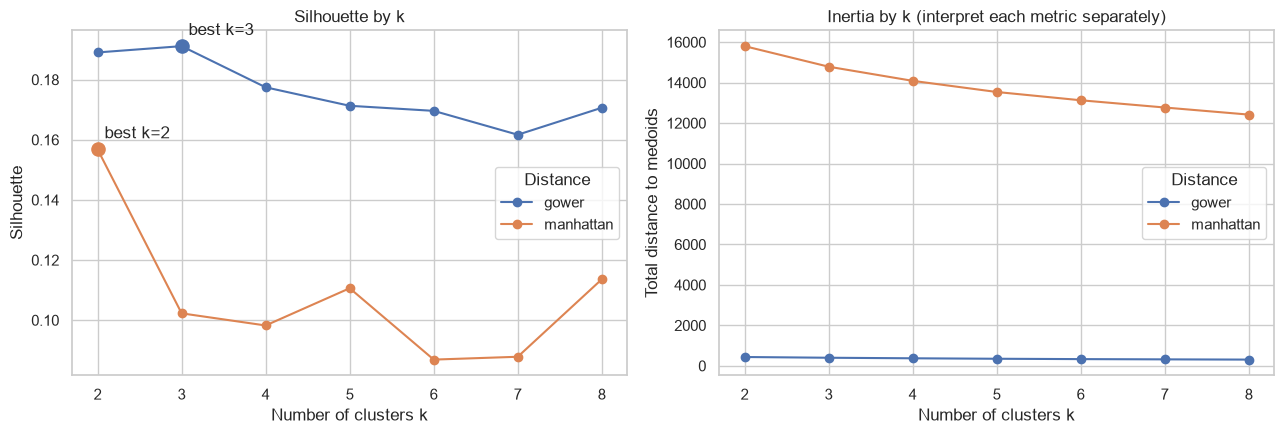

In [14]:
display(metrics.sort_values(["distance", "k"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for distance, group in metrics.groupby("distance"):
    group = group.sort_values("k")
    axes[0].plot(group["k"], group["silhouette"], marker="o", label=distance)
    axes[1].plot(group["k"], group["inertia"], marker="o", label=distance)
    best_k = int(config["best_k"][distance])
    best_row = group.loc[group["k"] == best_k].iloc[0]
    axes[0].scatter(best_k, best_row["silhouette"], s=90, zorder=3)
    axes[0].annotate(f"best k={best_k}", (best_k, best_row["silhouette"]),
                     xytext=(5, 8), textcoords="offset points")
axes[0].set(title="Silhouette by k", xlabel="Number of clusters k", ylabel="Silhouette")
axes[1].set(title="Inertia by k (interpret each metric separately)",
            xlabel="Number of clusters k", ylabel="Total distance to medoids")
for ax in axes:
    ax.legend(title="Distance")
    ax.set_xticks(sorted(metrics["k"].unique()))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_k_selection.png", dpi=160, bbox_inches="tight")
plt.show()


## 4. Kích thước cụm tại `k` được chọn

Xem quy mô và tỉ lệ từng cụm, kiểm tra cụm quá nhỏ hoặc phân bố mất cân bằng. Không kết luận chỉ dựa trên silhouette.

,distance,k,cluster,n,share
0,manhattan,2,0,1502,0.657906
1,manhattan,2,1,781,0.342094
2,gower,3,0,1173,0.513798
3,gower,3,1,609,0.266754
4,gower,3,2,501,0.219448


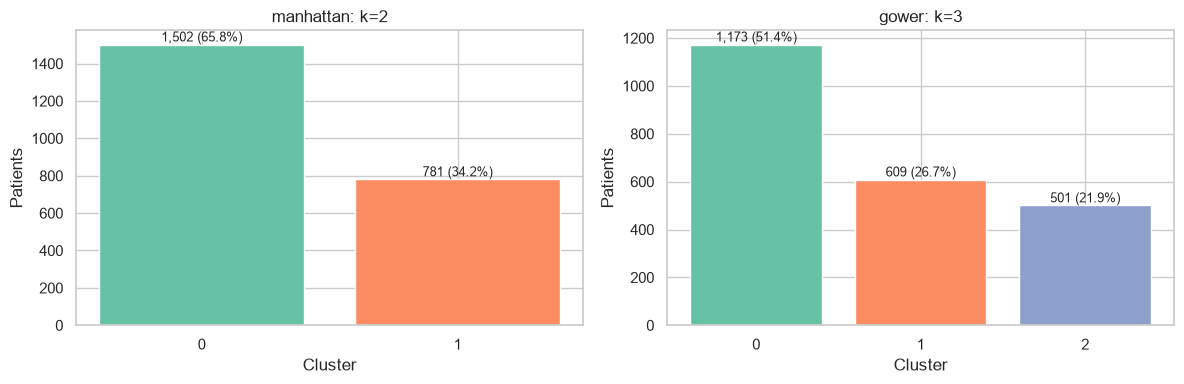

In [15]:
best_labels = {}
size_rows = []
for distance, best_k in config["best_k"].items():
    label_col = f"{distance}_k{best_k}"
    assert label_col in labels.columns, f"Missing label column: {label_col}"
    cluster_labels = labels[label_col].to_numpy()
    best_labels[distance] = (int(best_k), cluster_labels)
    counts = pd.Series(cluster_labels).value_counts().sort_index()
    for cluster_id, count in counts.items():
        size_rows.append({"distance": distance, "k": int(best_k),
                          "cluster": int(cluster_id), "n": int(count),
                          "share": float(count / n)})

cluster_sizes_best = pd.DataFrame(size_rows)
display(cluster_sizes_best)

fig, axes = plt.subplots(1, len(best_labels), figsize=(6 * len(best_labels), 4), squeeze=False)
for ax, (distance, (best_k, cluster_labels)) in zip(axes[0], best_labels.items()):
    counts = pd.Series(cluster_labels).value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values,
           color=sns.color_palette("Set2", len(counts)))
    ax.set(title=f"{distance}: k={best_k}", xlabel="Cluster", ylabel="Patients")
    for i, count in enumerate(counts.values):
        ax.text(i, count, f"{count:,} ({count/n:.1%})", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_cluster_sizes_best_k.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Manhattan và Gower có tạo cấu trúc cụm giống nhau không?

ARI đo mức độ tương đồng giữa hai cách chia cụm sau khi điều chỉnh cho kết quả ngẫu nhiên. ARI thấp không tự nó chứng minh mô hình nào sai; hai lần chạy này dùng metric khác nhau.

,k,ARI_manhattan_vs_gower
0,2,0.356
1,3,0.318
2,4,0.424
3,5,0.248
4,6,0.252
5,7,0.259
6,8,0.313


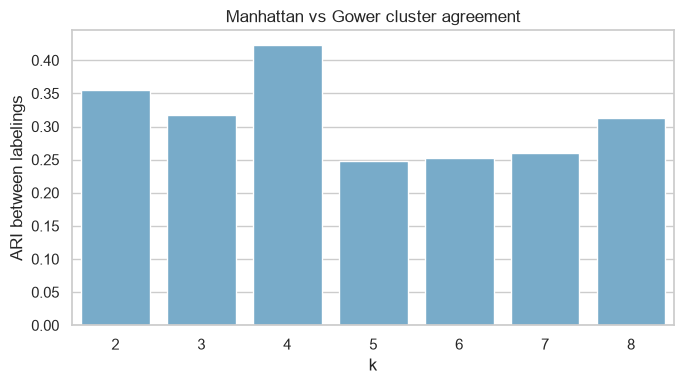

In [16]:
display(cross_method_ari.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=cross_method_ari, x="k", y="ARI_manhattan_vs_gower",
            color="#6baed6", ax=ax)
ax.set(title="Manhattan vs Gower cluster agreement",
       xlabel="k", ylabel="ARI between labelings")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_manhattan_vs_gower_ari.png", dpi=160, bbox_inches="tight")
plt.show()


## 6. Hồ sơ các cụm

Thống kê dùng giá trị gốc đã tiền xử lý trong `heart_dedup.csv`, không dùng one-hot để diễn giải. `target_rate` là thông tin hậu nghiệm.

In [17]:
profiles = {}
categorical_shares = {}
for distance, (best_k, cluster_labels) in best_labels.items():
    profiles[distance] = cluster_profile(patients, cluster_labels)
    print(f"\n{distance.upper()} | k={best_k} | numeric and binary profile")
    display(profiles[distance])

    tmp = patients[CATEGORICAL_COLS].copy()
    tmp["cluster"] = cluster_labels
    categorical_shares[distance] = {}
    for col in CATEGORICAL_COLS:
        shares = pd.crosstab(tmp["cluster"], tmp[col], normalize="index").round(3)
        categorical_shares[distance][col] = shares
        print(f"\n{distance.upper()} | {col} proportions within cluster")
        display(shares)



MANHATTAN | k=2 | numeric and binary profile


,n,age,trestbps,chol,thalach,oldpeak,sex_rate,fbs_rate,exang_rate,target_rate
cluster,,,,,,,,,,
0,1502,51.61,128.60,242.50,148.90,0.43,0.722,0.156,0.158,0.452
1,781,57.57,137.98,248.01,126.81,1.69,0.823,0.224,0.707,0.695



MANHATTAN | cp proportions within cluster


cp,1,2,3,4
cluster,,,,
0,0.025,0.211,0.274,0.490
1,0.010,0.233,0.060,0.697



MANHATTAN | restecg proportions within cluster


restecg,0,1,2
cluster,,,
0,0.587,0.262,0.151
1,0.534,0.273,0.193


... (14 outputs left out)


GOWER | ca proportions within cluster


ca,0,1,2,3
cluster,,,,
0,0.904,0.053,0.026,0.017
1,0.862,0.072,0.044,0.021
2,0.892,0.052,0.042,0.014



GOWER | thal proportions within cluster


thal,3,6,7
cluster,,,
0,0.084,0.033,0.883
1,0.026,0.034,0.939
2,0.168,0.008,0.824


## 7. Đối chiếu `target` sau phân cụm

Bảng chéo, ARI và purity là đánh giá hậu nghiệm; `target` không tham gia fit. Phân cụm không giám sát không nhất thiết phải tái tạo nhãn chẩn đoán; cần nêu rõ giới hạn này khi viết kết luận.

In [18]:
posthoc_results = {}
for distance, (best_k, cluster_labels) in best_labels.items():
    check = posthoc_target_check(cluster_labels, target)
    posthoc_results[distance] = {"k": best_k, **check}
    counts = pd.crosstab(pd.Series(cluster_labels, name="cluster"),
                         target.rename(TARGET_COL), margins=True)
    shares = pd.crosstab(pd.Series(cluster_labels, name="cluster"),
                         target.rename(TARGET_COL), normalize="index")
    print(f"\n{distance.upper()} | k={best_k} | target counts by cluster")
    display(counts)
    print("Target proportions within each cluster:")
    display(shares.round(3))

display(pd.DataFrame(posthoc_results).T.rename_axis("distance"))



MANHATTAN | k=2 | target counts by cluster


target,0,1,All
cluster,,,
0,823,679,1502
1,238,543,781
All,1061,1222,2283


Target proportions within each cluster:


target,0,1
cluster,,
0,0.548,0.452
1,0.305,0.695



GOWER | k=3 | target counts by cluster


target,0,1,All
cluster,,,
0,595,578,1173
1,171,438,609
2,295,206,501
All,1061,1222,2283


Target proportions within each cluster:


target,0,1
cluster,,
0,0.507,0.493
1,0.281,0.719
2,0.589,0.411


,k,ARI,purity
distance,,,
manhattan,2.0,0.037825,0.598336
gower,3.0,0.026139,0.581691


## 8. Xem các medoid

Medoid là một mẫu bệnh nhân thật được chọn làm đại diện cụm theo tổng khoảng cách. Chỉ số `medoid_index` được đối chiếu với đúng dòng trong `heart_dedup.csv`. Cột `target` chỉ hiển để tham khảo hậu nghiệm.

In [19]:
selected_medoids = []
for distance, (best_k, _) in best_labels.items():
    subset = medoids[(medoids["distance"] == distance) & (medoids["k"] == best_k)]
    subset = subset.sort_values("cluster").reset_index(drop=True)
    medoid_records = patients.iloc[subset["medoid_index"].to_numpy()].reset_index(drop=True)
    selected_medoids.append(pd.concat([subset, medoid_records], axis=1))
selected_medoids = pd.concat(selected_medoids, ignore_index=True)
display(selected_medoids)


,distance,k,cluster,medoid_index,age,trestbps,chol,thalach,oldpeak,cp,restecg,slope,ca,thal,sex,fbs,exang,target
0,manhattan,2,0,644,54,120.0,239.0,155.0,0.0,4,0,2,0,7,1.0,0,0,1
1,manhattan,2,1,1200,57,140.0,239.0,120.0,2.0,4,0,3,0,7,1.0,0,1,1
2,gower,3,0,833,50,130.0,218.0,143.0,0.5,4,0,2,0,7,1.0,0,0,1
3,gower,3,1,1335,58,137.0,232.0,124.0,1.4,4,1,3,0,7,1.0,0,1,1
4,gower,3,2,1788,51,130.0,256.0,149.0,0.5,4,0,2,0,7,0.0,0,0,1


## K-Medoids tự cài đặt trên toàn bộ ma trận đó với Manhattan, (k=2), seed 42.

In [20]:
from pathlib import Path
import sys
import pandas as pd
from sklearn.metrics import silhouette_score

# Nếu notebook đang ở thư mục notebooks thì thêm thư mục dự án vào đường dẫn.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.kmedoids import KMedoids
from src.evaluation import cluster_profile, posthoc_target_check
from src.data import TARGET_COL

PROCESSED = ROOT / "data" / "processed"

# Đọc các artifact đã xử lý. target được đọc riêng, không đưa vào mô hình.
patients = pd.read_csv(PROCESSED / "heart_dedup.csv")
X_manhattan = pd.read_csv(PROCESSED / "X_manhattan.csv")
target = pd.read_csv(PROCESSED / "target.csv")[TARGET_COL]

# Kiểm tra số dòng, thứ tự target và việc target không nằm trong X.
assert len(patients) == len(X_manhattan) == len(target) == 2283
assert TARGET_COL not in X_manhattan.columns
assert patients[TARGET_COL].equals(target)

# Chạy bản K-Medoids tự cài đặt.
model = KMedoids(
    n_clusters=2,
    metric="manhattan",
    random_state=42,
    max_iter=100,
).fit(X_manhattan.to_numpy(dtype=float))

labels = model.labels_

# Tạo bảng hồ sơ cụm; target_rate chỉ dùng cho phân tích hậu nghiệm.
profile = cluster_profile(patients, labels)
profile.insert(
    1,
    "percent",
    (profile["n"] / len(patients) * 100).round(2),
)

print("Số hồ sơ:", len(patients))
print("Kích thước cụm:", model.cluster_sizes_)
print("Medoid index (bắt đầu từ 0):", model.medoid_indices_)
print("Medoid nếu đánh số hồ sơ từ 1:", [i + 1 for i in model.medoid_indices_])
print("Objective/inertia:", round(model.inertia_, 6))
print("Số vòng lặp:", model.n_iter_)
print("Hội tụ:", model.converged_)
print("Silhouette:", round(
    silhouette_score(
        X_manhattan.to_numpy(dtype=float),
        labels,
        metric="manhattan",
    ),
    6,
))
print("Đối chiếu target hậu nghiệm:", posthoc_target_check(labels, target))

display(
    profile[
        [
            "n",
            "percent",
            "age",
            "trestbps",
            "chol",
            "thalach",
            "oldpeak",
            "target_rate",
        ]
    ]
)


Số hồ sơ: 2283
Kích thước cụm: [2084, 199]
Medoid index (bắt đầu từ 0): [2018, 88]
Medoid nếu đánh số hồ sơ từ 1: [2019, 89]
Objective/inertia: 17072.371705
Số vòng lặp: 2
Hội tụ: True
Silhouette: 0.201679
Đối chiếu target hậu nghiệm: {'ARI': 0.015081098370383971, 'purity': 0.5681121331581253}


,n,percent,age,trestbps,chol,thalach,oldpeak,target_rate
cluster,,,,,,,,
0,2084,91.28,53.68,131.59,243.63,140.09,0.87,0.557
1,199,8.72,53.34,134.09,252.24,154.44,0.73,0.312


Cái này là hồ sơ trung bình của mỗi cụm
Mỗi dòng mô tả cả cụm:

n, percent: số lượng và tỷ lệ hồ sơ trong cụm.
age, trestbps, chol, thalach, oldpeak: giá trị trung bình của các hồ sơ trong cụm.
target_rate: tỷ lệ hồ sơ trong cụm có target = 1, dùng để phân tích sau khi phân cụm.
Ví dụ, cụm 0 có 2.084 hồ sơ, tuổi trung bình 53,68 và target_rate = 0,557

--------------------------------------------------

In [21]:
# Tìm thư mục dự án; chạy được khi Jupyter mở ở thư mục gốc hoặc notebooks.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
ROOT = next(
    (p for p in candidates if (p / "src" / "kmedoids.py").is_file()),
    None,
)

# Nếu không tự tìm thấy, dùng đường dẫn dự án của bạn.
if ROOT is None:
    ROOT = Path(
        r"C:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids"
    )

if not (ROOT / "src" / "kmedoids.py").is_file():
    raise FileNotFoundError(f"Không tìm thấy mã nguồn tại: {ROOT}")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.kmedoids import KMedoids
from src.data import TARGET_COL

PROCESSED = ROOT / "data" / "processed"

# Đọc hồ sơ để diễn giải medoid và ma trận Manhattan để phân cụm.
patients = pd.read_csv(PROCESSED / "heart_dedup.csv")
X_manhattan = pd.read_csv(PROCESSED / "X_manhattan.csv")
target = pd.read_csv(PROCESSED / "target.csv")[TARGET_COL]

# Kiểm tra số dòng, thứ tự target và việc target không nằm trong đầu vào mô hình.
assert len(patients) == len(X_manhattan) == len(target) == 2283
assert TARGET_COL not in X_manhattan.columns
assert patients[TARGET_COL].equals(target)

# Chạy bản K-Medoids tự cài đặt trên toàn bộ dữ liệu.
model = KMedoids(
    n_clusters=2,
    metric="manhattan",
    random_state=42,
    max_iter=100,
).fit(X_manhattan.to_numpy(dtype=float))

# Tra hồ sơ thật tương ứng với medoid; medoid_indices_ bắt đầu từ 0.
medoid_rows = patients.iloc[model.medoid_indices_].reset_index(drop=True)

medoid_table = pd.DataFrame({
    "Cụm": range(model.n_clusters),
    "Medoid index, bắt đầu từ 0": model.medoid_indices_,
    "Hồ sơ, đánh số từ 1": [i + 1 for i in model.medoid_indices_],
    "Tuổi": medoid_rows["age"],
    "Huyết áp": medoid_rows["trestbps"],
    "Cholesterol": medoid_rows["chol"],
    "Nhịp tim tối đa": medoid_rows["thalach"],
    "Oldpeak": medoid_rows["oldpeak"],
    "target": medoid_rows[TARGET_COL],
})

print("Số hồ sơ:", len(patients))
print("Kích thước cụm:", model.cluster_sizes_)
print("Objective:", round(model.inertia_, 6))
print("Số vòng lặp:", model.n_iter_)
print("Hội tụ:", model.converged_)
display(medoid_table)


Số hồ sơ: 2283
Kích thước cụm: [2084, 199]
Objective: 17072.371705
Số vòng lặp: 2
Hội tụ: True


,Cụm,"Medoid index, bắt đầu từ 0","Hồ sơ, đánh số từ 1",Tuổi,Huyết áp,Cholesterol,Nhịp tim tối đa,Oldpeak,target
0,0,2018,2019,57,128.0,229.0,150.0,0.4,0
1,1,88,89,53,138.0,234.0,160.0,0.0,0


Cái này là hồ sơ đại diện thực tế
Mỗi dòng là một hồ sơ cụ thể được chọn làm medoid của cụm, chứ không phải giá trị trung bình:

Medoid index là vị trí bắt đầu từ 0 trong dữ liệu.
Hồ sơ là vị trí tương ứng nếu đánh số từ 1.
Các giá trị tuổi, huyết áp, cholesterol… là giá trị của đúng hồ sơ đó.
target là nhãn của hồ sơ medoid, không phải tỷ lệ của cả cụm.
Ví dụ, medoid của cụm 0 có tuổi 57 và target = 0. Điều đó không mâu thuẫn với tuổi trung bình 53,68 hay target_rate = 0,557 của cụm: medoid là một điểm đại diện, còn bảng đầu là thống kê tổng hợp.

## Ví dụ 30 hồ sơ bằng thư viện K-Medoids

Ô dưới đây gọi trực tiếp **`fit_kmedoids` từ `src/library_model.py` đã có của nhóm**. Các bước đọc dữ liệu, chọn mẫu, gọi mô hình và hiển thị kết quả đều nằm trong Notebook 2.

Dùng 30 dòng đầu của ma trận Manhattan đã fit trên toàn bộ dataset; 13 đặc trưng gốc trở thành 25 cột trong cấu hình gốc. Không fit lại scaler trên riêng 30 hồ sơ; không đưa target vào mô hình. Mô hình thư viện dùng PAM, BUILD, k=2, seed 42. Chỉ số từ 0; R1 tương ứng chỉ số 0. Các bảng được lưu riêng vào `outputs/library_30_records/` và cập nhật khi chạy lại ô này.


In [22]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display

# Bước 1: tìm project và sử dụng file thư viện đã có của nhóm.
cwd = Path.cwd().resolve()
root_30 = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "src" / "library_model.py").is_file()),
    None,
)
if root_30 is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án hoặc notebooks/.")
if str(root_30) not in sys.path:
    sys.path.insert(0, str(root_30))

from src.library_model import fit_kmedoids, METHOD, INIT
from src.data import FEATURE_COLS, TARGET_COL

# Bước 2: lấy 30 dòng đầu của cùng ma trận dùng cho ví dụ tính tay.
# 13 đặc trưng gốc -> 25 cột đã xử lý trong cấu hình gốc.
# Bộ scaler đã fit trên toàn bộ dataset, không fit lại trên riêng 30 dòng.
processed_30 = root_30 / "data" / "processed"
matrix_path_30 = processed_30 / "X_manhattan.csv"
features_30 = pd.read_csv(matrix_path_30)
patients_30 = pd.read_csv(processed_30 / "heart_dedup.csv")
if len(features_30) != len(patients_30) or len(features_30) < 30:
    raise ValueError("Hai file processed phải cùng số dòng và có ít nhất 30 hồ sơ.")
if TARGET_COL in features_30.columns or "source" in features_30.columns:
    raise ValueError("Ma trận phân cụm không được chứa target hoặc source.")
X_30_library = features_30.iloc[:30].to_numpy(dtype=float)
if not np.isfinite(X_30_library).all():
    raise ValueError("Đầu vào còn NaN hoặc giá trị vô hạn.")

# Bước 3: gọi trực tiếp adapter đã có trong src/library_model.py.
result_30_library = fit_kmedoids(
    data=X_30_library,
    n_clusters=2,
    metric="manhattan",
    random_state=42,
)
labels_30_library = result_30_library.labels
medoid_indices_30_library = result_30_library.medoid_indices

# Bước 4: tính khoảng cách đến medoid để trình bày từng nhãn được gán.
distances_30_library = np.abs(
    X_30_library[:, None, :] - X_30_library[medoid_indices_30_library][None, :, :]
).sum(axis=2)
assignments_30_library = pd.DataFrame({"record": [f"R{i+1}" for i in range(30)]})
for c, idx in enumerate(medoid_indices_30_library):
    assignments_30_library[f"distance_to_R{int(idx)+1}"] = distances_30_library[:, c]
assignments_30_library["cluster"] = labels_30_library
assignments_30_library["medoid_record"] = [
    f"R{int(medoid_indices_30_library[c])+1}" for c in labels_30_library
]
assignments_30_library["assigned_distance"] = distances_30_library[
    np.arange(30), labels_30_library
]

# Bước 5: bảng thành viên và hồ sơ gốc của hai medoid.
clusters_30_library = pd.DataFrame([
    {"cluster": c, "medoid": f"R{int(medoid_indices_30_library[c])+1}",
     "records": ", ".join(assignments_30_library.loc[labels_30_library == c, "record"]),
     "n_records": int((labels_30_library == c).sum()),
     "total_distance": float(assignments_30_library.loc[
         labels_30_library == c, "assigned_distance"].sum())}
    for c in range(2)
])
medoids_30_library = patients_30.iloc[medoid_indices_30_library][FEATURE_COLS].copy()
medoids_30_library.insert(0, "record", [f"R{int(i)+1}" for i in medoid_indices_30_library])
medoids_30_library.insert(0, "cluster", np.arange(2))
summary_30_library = {
    "n_records": 30,
    "n_original_features": len(FEATURE_COLS),
    "n_transformed_features": X_30_library.shape[1],
    "method": METHOD, "init": INIT, "metric": "manhattan", "random_state": 42,
    "selection": "First 30 rows of the saved full-data transformed matrix",
    "medoid_indices_zero_based": medoid_indices_30_library.tolist(),
    "medoid_records": medoids_30_library["record"].tolist(),
    "cluster_sizes": np.bincount(labels_30_library, minlength=2).tolist(),
    "labels": labels_30_library.tolist(),
    "inertia": float(result_30_library.inertia), "n_iter": result_30_library.n_iter,
    "matrix_sha256": hashlib.sha256(matrix_path_30.read_bytes()).hexdigest(),
    "target_used_for_fit": False,
}
print("Số hồ sơ:", summary_30_library["n_records"])
print("Đặc trưng gốc / cột sau xử lý:", len(FEATURE_COLS), "/", X_30_library.shape[1])
print("Medoid:", summary_30_library["medoid_records"])
print("Kích thước cụm:", summary_30_library["cluster_sizes"])
print(f"Tổng khoảng cách: {result_30_library.inertia:.6f}")
display(clusters_30_library.round(6))
display(medoids_30_library)
display(assignments_30_library.round(6))

# Bước 6: lưu kết quả ví dụ vào thư mục riêng, cập nhật khi chạy lại ô này.
output_30_library = root_30 / "outputs" / "library_30_records"
output_30_library.mkdir(parents=True, exist_ok=True)
assignments_30_library.to_csv(output_30_library / "assignments.csv", index=False)
clusters_30_library.to_csv(output_30_library / "clusters.csv", index=False)
medoids_30_library.to_csv(output_30_library / "medoids.csv", index=False)
(output_30_library / "summary.json").write_text(
    json.dumps(summary_30_library, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Kết quả lưu tại:", output_30_library)


Số hồ sơ: 30
Đặc trưng gốc / cột sau xử lý: 13 / 25
Medoid: ['R20', 'R25']
Kích thước cụm: [19, 11]
Tổng khoảng cách: 210.033031


,cluster,medoid,records,n_records,total_distance
0,0,R20,"R4, R5, R6, R8, R11, R12, R14, R15, R16, R17, ...",19,127.603111
1,1,R25,"R1, R2, R3, R7, R9, R10, R13, R21, R24, R25, R30",11,82.429920


,cluster,record,age,trestbps,chol,thalach,oldpeak,cp,restecg,slope,ca,thal,sex,fbs,exang
19,0,R20,49,130.0,266.0,171.0,0.6,2,0,1,0,3,1.0,0,0
24,1,R25,60,130.0,206.0,132.0,2.4,4,2,2,2,7,1.0,0,1


,record,distance_to_R20,distance_to_R25,cluster,medoid_record,assigned_distance
0,R1,14.374748,12.488037,1,R25,12.488037
1,R2,16.314603,9.756966,1,R25,9.756966
2,R3,17.705519,2.054219,1,R25,2.054219
3,R4,8.904644,17.491181,0,R20,8.904644
4,R5,5.826757,14.569650,0,R20,5.826757
5,R6,2.347493,15.869022,0,R20,2.347493
6,R7,14.198044,10.189973,1,R25,10.189973
7,R8,7.426164,15.628546,0,R20,7.426164
8,R9,13.411821,5.764449,1,R25,5.764449
9,R10,15.151142,7.923598,1,R25,7.923598


Kết quả lưu tại: C:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\library_30_records


## Tạo và lưu 5 hình bổ sung cho báo cáo

| Tệp ảnh | Nội dung |
| --- | --- |
| `eda_missing.png` | Tỷ lệ thiếu của 13 đặc trưng trong dữ liệu thô |
| `eda_sources_target.png` | Số hồ sơ theo target và nguồn dữ liệu |
| `eda_numeric.png` | Phân bố 5 đặc trưng số trước tiền xử lý |
| `sensitivity_silhouette.png` | So sánh Silhouette giữa miền mã baseline và miền mở rộng |
| `custom_source_composition.png` | Tỷ lệ từng nguồn trong mỗi cụm của mô hình tự cài đặt |

Ô này có đầy đủ import và tự tìm thư mục dự án, chạy được độc lập khi mở Jupyter
tại thư mục gốc hoặc `notebooks/`. Nó đọc dữ liệu và kết quả CSV đã có để vẽ;
không chạy lại K-Medoids. Nếu thiếu đầu vào, ô sẽ báo rõ đường dẫn cần có.
Thay đổi dữ liệu/thực nghiệm cần tái tạo các kết quả đầu vào tương ứng trước khi vẽ.

Lệnh ghi ảnh thật sự là `fig.savefig(...)` trong hàm `save_report_figure`.
`display(fig)` chỉ hiển thị hình trong notebook. Ba hình so sánh chính ở mục 3–5
đã có lệnh lưu riêng vào `outputs/figures/`.


Đã lưu: C:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\report_completion_20261105\eda_missing.png


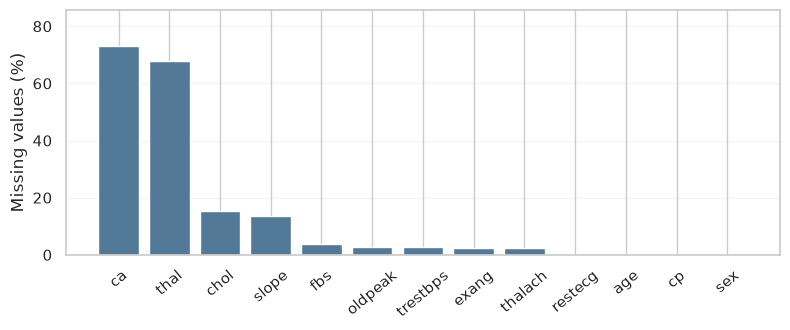

Đã lưu: C:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\report_completion_20261105\eda_sources_target.png


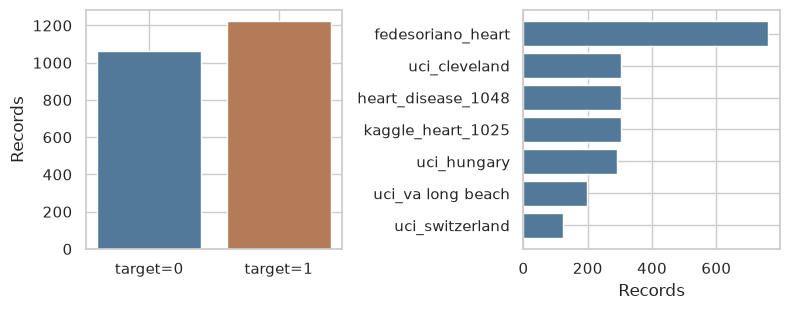

Đã lưu: C:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\report_completion_20261105\eda_numeric.png


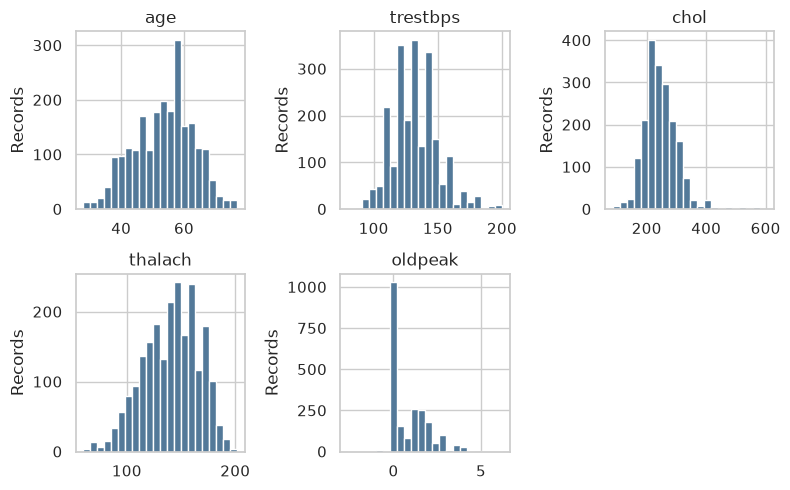

Đã lưu: C:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\report_completion_20261105\sensitivity_silhouette.png


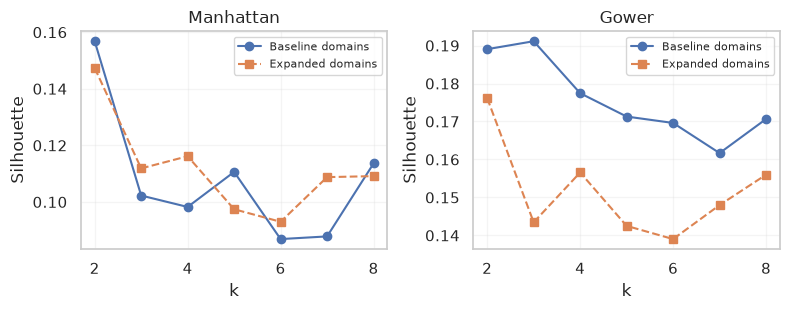

Đã lưu: C:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\report_completion_20261105\custom_source_composition.png


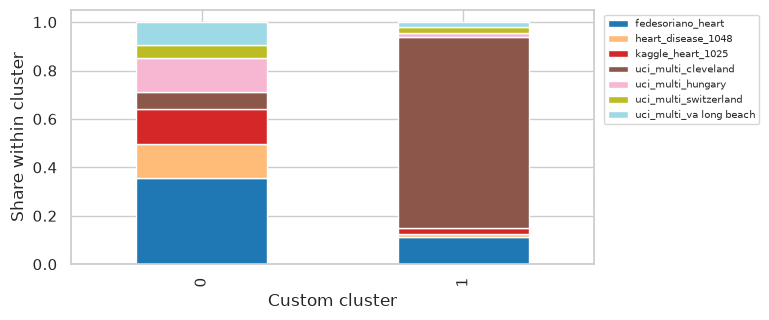

Hoàn tất: 5 ảnh PNG tại C:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\report_completion_20261105


In [23]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Bước 1: Tìm thư mục dự án, không hard-code đường dẫn OneDrive của một máy.
cwd = Path.cwd().resolve()
report_root = next(
    (p for p in [cwd, *cwd.parents] if (p / "src/library_model.py").is_file()),
    None,
)
if report_root is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục dự án hoặc notebooks/.")
if str(report_root) not in sys.path:
    sys.path.insert(0, str(report_root))
from src.data import FEATURE_COLS, NUMERIC_COLS

report_figure_dir = report_root / "outputs/report_completion_20261105"
report_inputs = {
    "raw": report_root / "data/raw/heart_disease_whole.csv",
    "baseline": report_root / "outputs/metrics/k_selection.csv",
    "sensitivity": report_figure_dir / "sensitivity_k_selection.csv",
    "sources": report_figure_dir / "baseline_custom_k2_sources.csv",
}
missing_files = [str(path) for path in report_inputs.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Thiếu đầu vào để vẽ:\n" + "\n".join(missing_files))

# Bước 2: Đọc dữ liệu thô và kết quả đã lưu; không fit lại mô hình.
report_raw = pd.read_csv(report_inputs["raw"])
report_baseline = pd.read_csv(report_inputs["baseline"])
report_sensitivity = pd.read_csv(report_inputs["sensitivity"])
report_sources = pd.read_csv(report_inputs["sources"], index_col=0)
report_figure_dir.mkdir(parents=True, exist_ok=True)
saved_report_figures = []

def save_report_figure(fig, filename):
    """Lưu PNG vào ổ đĩa, hiển thị trong notebook và giải phóng figure."""
    path = report_figure_dir / filename
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")  # Lệnh lưu ảnh chính thức.
    saved_report_figures.append(path)
    print(f"Đã lưu: {path}")
    display(fig)
    plt.close(fig)

# Bước 3: Tạo và lưu từng hình. rc_context chỉ áp dụng style trong ô này.
with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10}):
    # Hình 1: Tỷ lệ thiếu ở dữ liệu thô, trước làm sạch và điền thiếu.
    missing_percent = report_raw[FEATURE_COLS].isna().mean().sort_values(ascending=False) * 100
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.bar(missing_percent.index, missing_percent.values, color="#537999")
    ax.set_ylabel("Missing values (%)")
    ax.set_ylim(0, max(1.0, float(missing_percent.max()) * 1.17))
    ax.tick_params(axis="x", rotation=40)
    ax.grid(axis="y", alpha=0.2)
    save_report_figure(fig, "eda_missing.png")

    # Hình 2: Target dùng mô tả/đối chiếu, không phải đặc trưng phân cụm.
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
    target_counts = report_raw["target"].value_counts().reindex([0, 1], fill_value=0)
    axes[0].bar(["target=0", "target=1"], target_counts.values, color=["#537999", "#b47c56"])
    axes[0].set_ylabel("Records")
    source_counts = report_raw["source"].value_counts()
    axes[1].barh(
        [str(source).replace("uci_multi_", "uci_") for source in source_counts.index],
        source_counts.values, color="#537999",
    )
    axes[1].invert_yaxis()
    axes[1].set_xlabel("Records")
    save_report_figure(fig, "eda_sources_target.png")

    # Hình 3: Histogram của 5 biến số; bỏ giá trị thiếu khi vẽ.
    fig, axes = plt.subplots(2, 3, figsize=(8, 5))
    for ax, column in zip(axes.flat, NUMERIC_COLS):
        ax.hist(report_raw[column].dropna(), bins=22, color="#537999", edgecolor="white")
        ax.set_title(column)
        ax.set_ylabel("Records")
    axes.flat[-1].axis("off")
    save_report_figure(fig, "eda_numeric.png")

    # Hình 4: Hai chính sách miền mã đã thực nghiệm; giữ riêng các kết quả.
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
    for ax, distance in zip(axes, ["manhattan", "gower"]):
        baseline = report_baseline.loc[report_baseline["distance"] == distance].sort_values("k")
        sensitivity = report_sensitivity.loc[report_sensitivity["distance"] == distance].sort_values("k")
        ax.plot(baseline["k"], baseline["silhouette"], "o-", label="Baseline domains")
        ax.plot(sensitivity["k"], sensitivity["silhouette"], "s--", label="Expanded domains")
        ax.set_title(distance.capitalize())
        ax.set_xlabel("k")
        ax.set_ylabel("Silhouette")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    save_report_figure(fig, "sensitivity_silhouette.png")

    # Hình 5: Mỗi cột là một cụm; các phần màu cộng lại thành 100%.
    fig, ax = plt.subplots(figsize=(7.8, 3.3))
    source_shares = report_sources.div(report_sources.sum(axis=1), axis=0)
    source_shares.plot.bar(stacked=True, ax=ax, colormap="tab20")
    ax.set_ylabel("Share within cluster")
    ax.set_xlabel("Custom cluster")
    ax.legend(bbox_to_anchor=(1.01, 1), fontsize=7)
    save_report_figure(fig, "custom_source_composition.png")

print(f"Hoàn tất: {len(saved_report_figures)} ảnh PNG tại {report_figure_dir}")
